# Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path

# TensorFlow & Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Evaluation Libraries
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
tf.random.set_seed(42)


# Define Path, Size & Classes

In [4]:
TRAIN_DIR = 'Dataset/Training'  
TEST_DIR = 'Dataset/Testing'    


IMG_SIZE = 128  
BATCH_SIZE = 32  
EPOCHS = 30 


CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
NUM_CLASSES = len(CLASSES)

print(f"Number of Classes: {NUM_CLASSES}")
print(f"Name of Classes: {CLASSES}")

Number of Classes: 4
Name of Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


# Preprocessing

In [6]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.1,
    validation_split=0.2
)

val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Normalize Test Data
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='training',
    shuffle=True
)

val_generator = val_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    subset='validation',
    shuffle=False
)

# Load Test Data
test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print(f"\n Number Of Train Images : {train_generator.samples}")
print(f" Number Of Validation Images: {val_generator.samples}")
print(f" Number Of Test Images: {test_generator.samples}")

Found 320 images belonging to 4 classes.
Found 80 images belonging to 4 classes.
Found 80 images belonging to 4 classes.

 Number Of Train Images : 320
 Number Of Validation Images: 80
 Number Of Test Images: 80


# Show Some Sample Of Each Classes

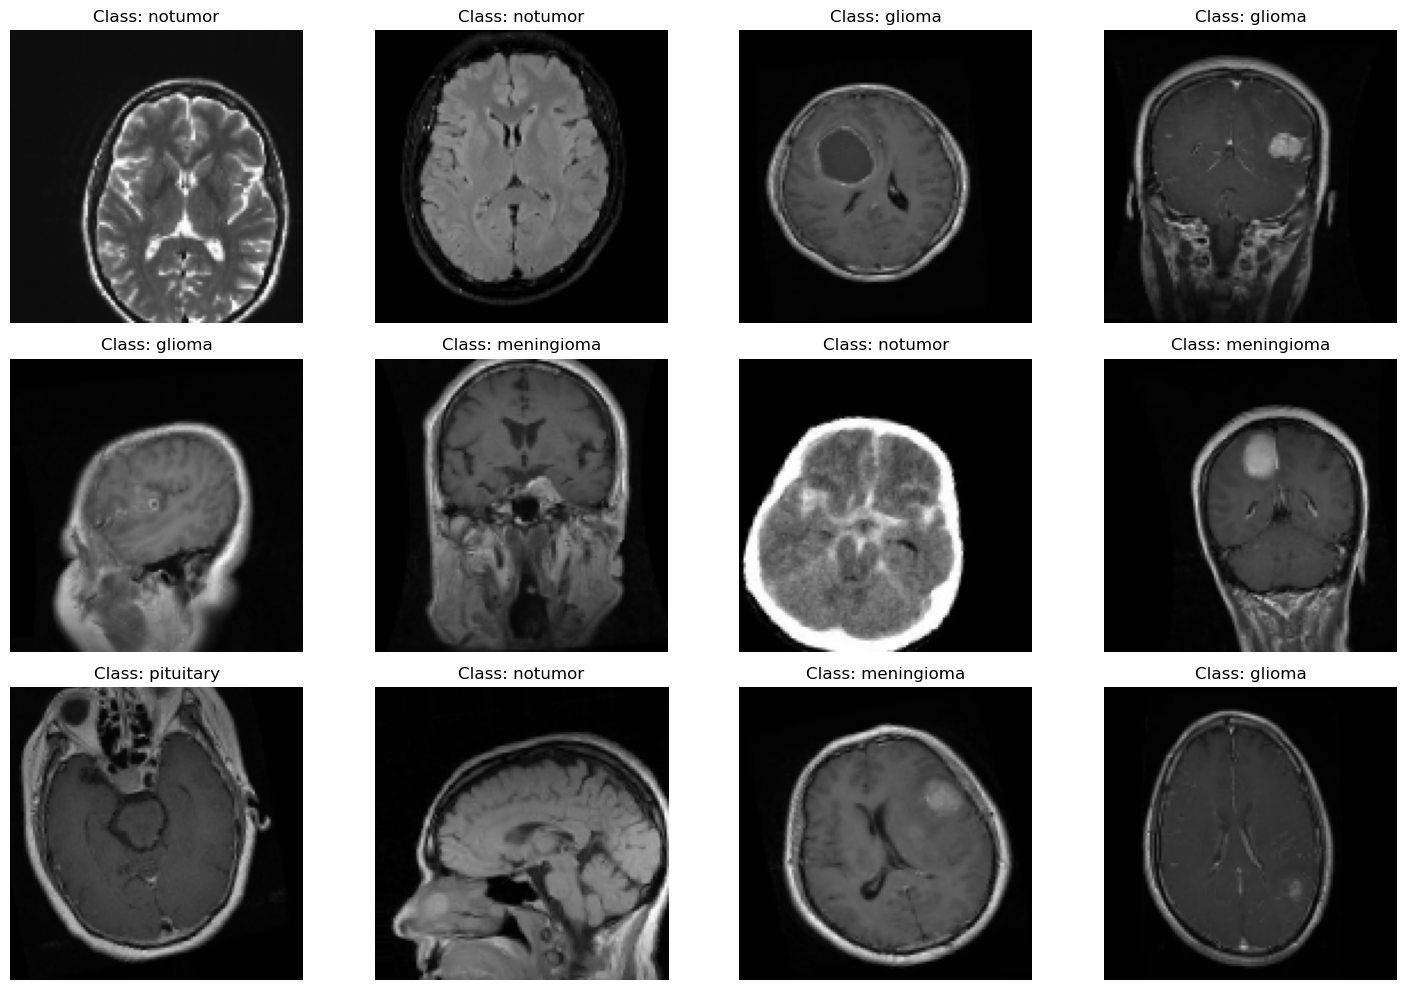

In [8]:

plt.figure(figsize=(15, 10))
sample_images, sample_labels = next(train_generator)

for i in range(min(12, len(sample_images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(sample_images[i])
    class_index = np.argmax(sample_labels[i])
    plt.title(f"Class: {CLASSES[class_index]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# 1. Define Simple CNN Model

In [10]:
def create_simple_cnn():
 
    model = models.Sequential([
        
        layers.Conv2D(32, (3, 3), activation='relu', input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.MaxPooling2D((2, 2)),
        
        
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
      
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.MaxPooling2D((2, 2)),
        
       
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    
    return model


model_1 = create_simple_cnn()
model_1.summary()


model_1.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

# 2. VGG Modle

In [12]:
def create_vgg_like_cnn():
  
    model = models.Sequential([
      
        layers.Conv2D(32, (3, 3), activation='relu', padding='same', 
                     input_shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.BatchNormalization(),
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
       
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
      
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),
        
        # لایه‌های Fully Connected
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(128, activation='relu'),
        layers.BatchNormalization(),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])
    
    return model

model_2 = create_vgg_like_cnn()
model_2.summary()

model_2.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 8,712,612 (33.24 MB)

 Trainable params: 8,710,948 (33.23 MB)

 Non-trainable params: 1,664 (6.50 KB)

# 3. ResNet Model

In [14]:
def residual_block(x, filters, kernel_size=3):
 
    y = layers.Conv2D(filters, kernel_size, padding='same')(x)
    y = layers.BatchNormalization()(y)
    y = layers.Activation('relu')(y)
    
    y = layers.Conv2D(filters, kernel_size, padding='same')(y)
    y = layers.BatchNormalization()(y)
    
    if x.shape[-1] != filters:
        x = layers.Conv2D(filters, 1, padding='same')(x)
    
    out = layers.Add()([x, y])
    out = layers.Activation('relu')(out)
    
    return out

def create_resnet_like():

    inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    
    x = layers.Conv2D(32, 3, padding='same')(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.Activation('relu')(x)
    
    x = residual_block(x, 32)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)
    
    x = residual_block(x, 64)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)
    
    x = residual_block(x, 128)
    x = layers.MaxPooling2D(2)(x)
    x = layers.Dropout(0.25)(x)
    
    x = residual_block(x, 256)
    x = layers.GlobalAveragePooling2D()(x)
    
    x = layers.Dense(256, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    
    model = models.Model(inputs=inputs, outputs=outputs)
    
    return model

model_3 = create_resnet_like()
model_3.summary()

model_3.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │        896 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │      9,248 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 128, 128,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │      9,248 │ activation_1[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        128 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 128, 128,  │          0 │ activation[0][0], │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 128, 128,  │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 64, 64,    │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_6[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │     18,496 │ dropout_6[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_12[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 64, 64,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     36,928 │ activation_3[0][

 Total params: 1,296,772 (4.95 MB)

 Trainable params: 1,294,276 (4.94 MB)

 Non-trainable params: 2,496 (9.75 KB)

# Define Callbacks for Better training

In [16]:
# EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Reduce LR On Plateau
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-7,
    verbose=1
)

callbacks = [early_stopping, reduce_lr]

# Training Simple CNN

In [18]:
print("="*50)
print("Training Simple CNN")
print("="*50)

history_1 = model_1.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Training Simple CNN
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 922ms/step - accuracy: 0.3906 - loss: 1.2945 - val_accuracy: 0.6875 - val_loss: 0.9622 - learning_rate: 0.0010
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 8s 855ms/step - accuracy: 0.4594 - loss: 1.1007 - val_accuracy: 0.6375 - val_loss: 0.8709 - learning_rate: 0.0010
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 11s 1s/step - accuracy: 0.5219 - loss: 1.0102 - val_accuracy: 0.6875 - val_loss: 0.8224 - learning_rate: 0.0010
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 10s 945ms/step - accuracy: 0.5375 - loss: 0.9574 - val_accuracy: 0.6875 - val_loss: 0.8092 - learning_rate: 0.0010
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 905ms/step - accuracy: 0.5594 - loss: 0.9566 - val_accuracy: 0.8125 - val_loss: 0.6943 - learning_rate: 0.0010
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 911ms/step - accuracy: 0.5219 - loss: 0.9270 - val_accuracy: 0.7500 - val_loss: 0.7414 - learning_rate: 0.0010
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 9s 894ms/step - accuracy: 0.60

# Training VGG Model

In [20]:
print("="*50)
print("Training VGG Model")
print("="*50)

history_2 = model_2.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Training VGG Model
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 54s 4s/step - accuracy: 0.4187 - loss: 1.8204 - val_accuracy: 0.4375 - val_loss: 1.3810 - learning_rate: 0.0010
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step - accuracy: 0.5781 - loss: 1.0992 - val_accuracy: 0.4750 - val_loss: 1.4845 - learning_rate: 0.0010
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.5949 - loss: 1.2319
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
10/10 ━━━━━━━━━━━━━━━━━━━━ 42s 4s/step - accuracy: 0.6125 - loss: 1.1312 - val_accuracy: 0.2500 - val_loss: 1.6769 - learning_rate: 0.0010
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step - accuracy: 0.6406 - loss: 1.0113 - val_accuracy: 0.2500 - val_loss: 2.0034 - learning_rate: 5.0000e-04
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 44s 4s/step - accuracy: 0.6719 - loss: 0.9581 - val_accuracy: 0.2500 - val_loss: 1.8903 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the best ep

# Training ResNet Model

In [22]:
print("="*50)
print("Training ResNet Model")
print("="*50)

history_3 = model_3.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=val_generator,
    callbacks=callbacks,
    verbose=1
)

Training ResNet Model
Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 82s 7s/step - accuracy: 0.5969 - loss: 1.1017 - val_accuracy: 0.2500 - val_loss: 1.8826 - learning_rate: 0.0010
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 59s 6s/step - accuracy: 0.6687 - loss: 0.8720 - val_accuracy: 0.3375 - val_loss: 1.3891 - learning_rate: 0.0010
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 5s/step - accuracy: 0.6784 - loss: 0.8570
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
10/10 ━━━━━━━━━━━━━━━━━━━━ 58s 6s/step - accuracy: 0.6625 - loss: 0.8948 - val_accuracy: 0.3125 - val_loss: 1.3850 - learning_rate: 0.0010
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 60s 6s/step - accuracy: 0.6531 - loss: 0.8500 - val_accuracy: 0.2625 - val_loss: 1.4795 - learning_rate: 5.0000e-04
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 60s 6s/step - accuracy: 0.7063 - loss: 0.7523 - val_accuracy: 0.2625 - val_loss: 1.4385 - learning_rate: 5.0000e-04
Epoch 5: early stopping
Restoring model weights from the end of the best

# Plot Accuracy & Loss Diagram

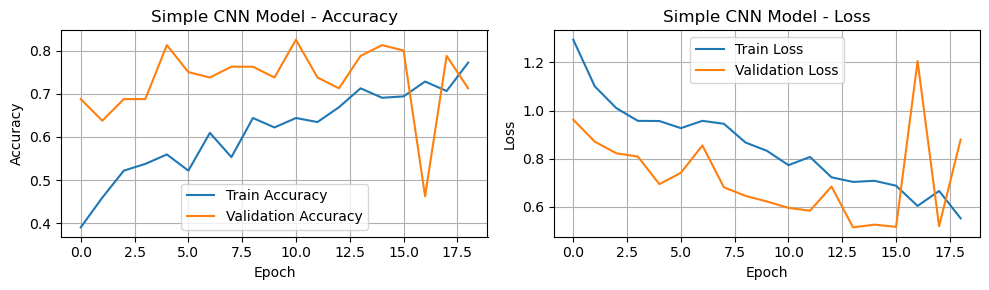

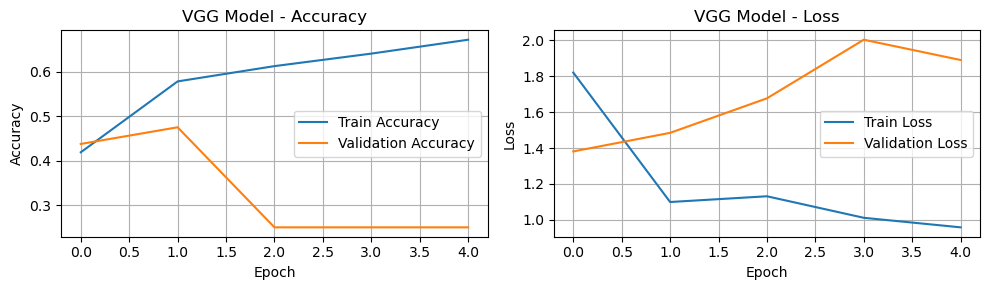

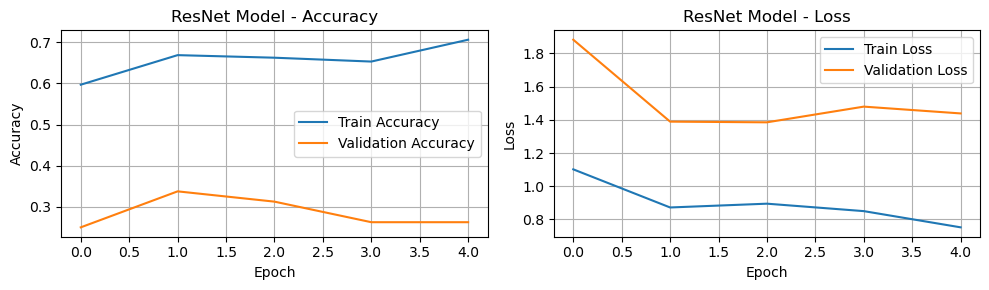

In [58]:
def plot_training_history(history, model_name):
  
    fig, axes = plt.subplots(1, 2, figsize=(10, 3))
    
    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train Accuracy')
    axes[0].plot(history.history['val_accuracy'], label='Validation Accuracy')
    axes[0].set_title(f'{model_name} - Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True)
    
    # Loss
    axes[1].plot(history.history['loss'], label='Train Loss')
    axes[1].plot(history.history['val_loss'], label='Validation Loss')
    axes[1].set_title(f'{model_name} - Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True)
    
    plt.tight_layout()
    plt.show()


plot_training_history(history_1, 'Simple CNN Model')
plot_training_history(history_2, 'VGG Model')
plot_training_history(history_3, 'ResNet Model')

# Evaluate Models

In [26]:
def evaluate_model(model, model_name, test_gen):
  
    print(f"\n{'='*60}")
    print(f"Evaluate Model: {model_name}")
    print(f"{'='*60}\n")
    
    test_gen.reset()
    y_pred_probs = model.predict(test_gen, verbose=1)
    y_pred = np.argmax(y_pred_probs, axis=1)
    y_true = test_gen.classes
    
    # Compute Evaluation Metrics
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, average='weighted')
    recall = recall_score(y_true, y_pred, average='weighted')
    f1 = f1_score(y_true, y_pred, average='weighted')
    
    print(f"Accuracy:  {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1-Score:  {f1:.4f}")
    
    print("\nReport:")
    print(classification_report(y_true, y_pred, target_names=CLASSES))
    
    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)
    
    return {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1_score': f1,
        'confusion_matrix': cm,
        'y_true': y_true,
        'y_pred': y_pred
    }

results_1 = evaluate_model(model_1, 'Simple CNN Model', test_generator)
results_2 = evaluate_model(model_2, 'VGG Model', test_generator)
results_3 = evaluate_model(model_3, 'ResNet Model', test_generator)


Evaluate Model: Simple CNN Model

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 372ms/step
Accuracy:  0.3500
Precision: 0.3557
Recall:    0.3500
F1-Score:  0.3034

Report:
              precision    recall  f1-score   support

      glioma       0.85      0.55      0.67        20
  meningioma       0.00      0.00      0.00        20
     notumor       0.33      0.80      0.46        20
   pituitary       0.25      0.05      0.08        20

    accuracy                           0.35        80
   macro avg       0.36      0.35      0.30        80
weighted avg       0.36      0.35      0.30        80


Evaluate Model: VGG Model

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 791ms/step
Accuracy:  0.3750
Precision: 0.3531
Recall:    0.3750
F1-Score:  0.2994

Report:
              precision    recall  f1-score   support

      glioma       0.00      0.00      0.00        20
  meningioma       0.28      0.80      0.42        20
     notumor       0.50      0.10      0.17        20
   pituitary       0.63      0.60      0.62  

# Confusion Matrix For Each Model

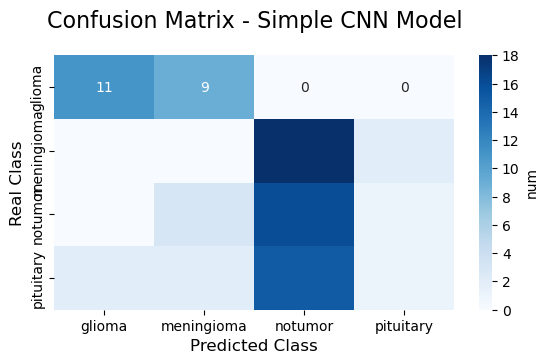

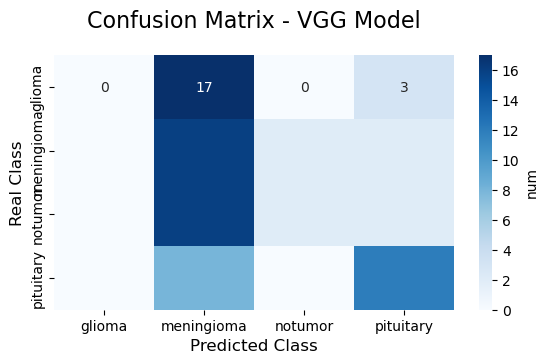

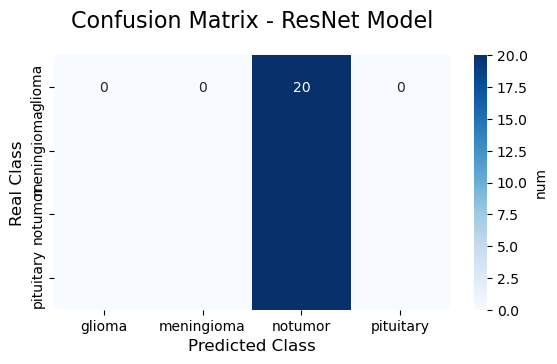

In [68]:
def plot_confusion_matrix(cm, model_name):
  
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=CLASSES, yticklabels=CLASSES,
                cbar_kws={'label': 'num'})
    plt.title(f'Confusion Matrix - {model_name}', fontsize=16, pad=20)
    plt.ylabel('Real Class', fontsize=12)
    plt.xlabel('Predicted Class', fontsize=12)
    plt.tight_layout()
    plt.show()

# Confusion Matrix
plot_confusion_matrix(results_1['confusion_matrix'], 'Simple CNN Model')
plot_confusion_matrix(results_2['confusion_matrix'], 'VGG Model')
plot_confusion_matrix(results_3['confusion_matrix'], 'ResNet Model')

# Comparing Models

In [30]:
# create comparing table
comparison_df = pd.DataFrame({
    'Model': ['Simple CNN', 'VGG', 'ResNet'],
    'Accuracy': [
        results_1['accuracy'],
        results_2['accuracy'],
        results_3['accuracy']
    ],
    'Precision': [
        results_1['precision'],
        results_2['precision'],
        results_3['precision']
    ],
    'Recall': [
        results_1['recall'],
        results_2['recall'],
        results_3['recall']
    ],
    'F1-Score': [
        results_1['f1_score'],
        results_2['f1_score'],
        results_3['f1_score']
    ]
})

print("\n" + "="*70)
print("Models Performance Comparison Table")
print("="*70)
print(comparison_df.to_string(index=False))
print("="*70)

# ذخیره جدول به فایل CSV
comparison_df.to_csv('model_comparison.csv', index=False)
print("\n Comparison Table Saved In 'model_comparison.csv'")


Models Performance Comparison Table
     Model  Accuracy  Precision  Recall  F1-Score
Simple CNN     0.350   0.355671   0.350  0.303442
       VGG     0.375   0.353070   0.375  0.299409
    ResNet     0.250   0.062500   0.250  0.100000

 Comparison Table Saved In 'model_comparison.csv'


# Comparison Metrics Diagram

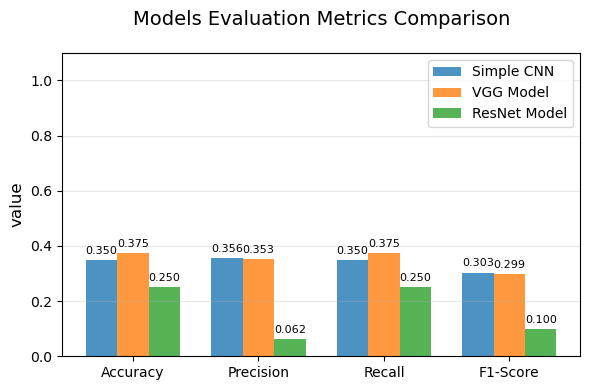

In [64]:

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(6, 4))

model1_scores = [results_1['accuracy'], results_1['precision'], 
                 results_1['recall'], results_1['f1_score']]
model2_scores = [results_2['accuracy'], results_2['precision'], 
                 results_2['recall'], results_2['f1_score']]
model3_scores = [results_3['accuracy'], results_3['precision'], 
                 results_3['recall'], results_3['f1_score']]

rects1 = ax.bar(x - width, model1_scores, width, label='Simple CNN', alpha=0.8)
rects2 = ax.bar(x, model2_scores, width, label='VGG Model', alpha=0.8)
rects3 = ax.bar(x + width, model3_scores, width, label='ResNet Model', alpha=0.8)

ax.set_ylabel('value', fontsize=12)
ax.set_title('Models Evaluation Metrics Comparison', fontsize=14, pad=20)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim([0, 1.1])
ax.grid(axis='y', alpha=0.3)


def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=8)

autolabel(rects1)
autolabel(rects2)
autolabel(rects3)

plt.tight_layout()
plt.show()

# Show Some Predicted Samples

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


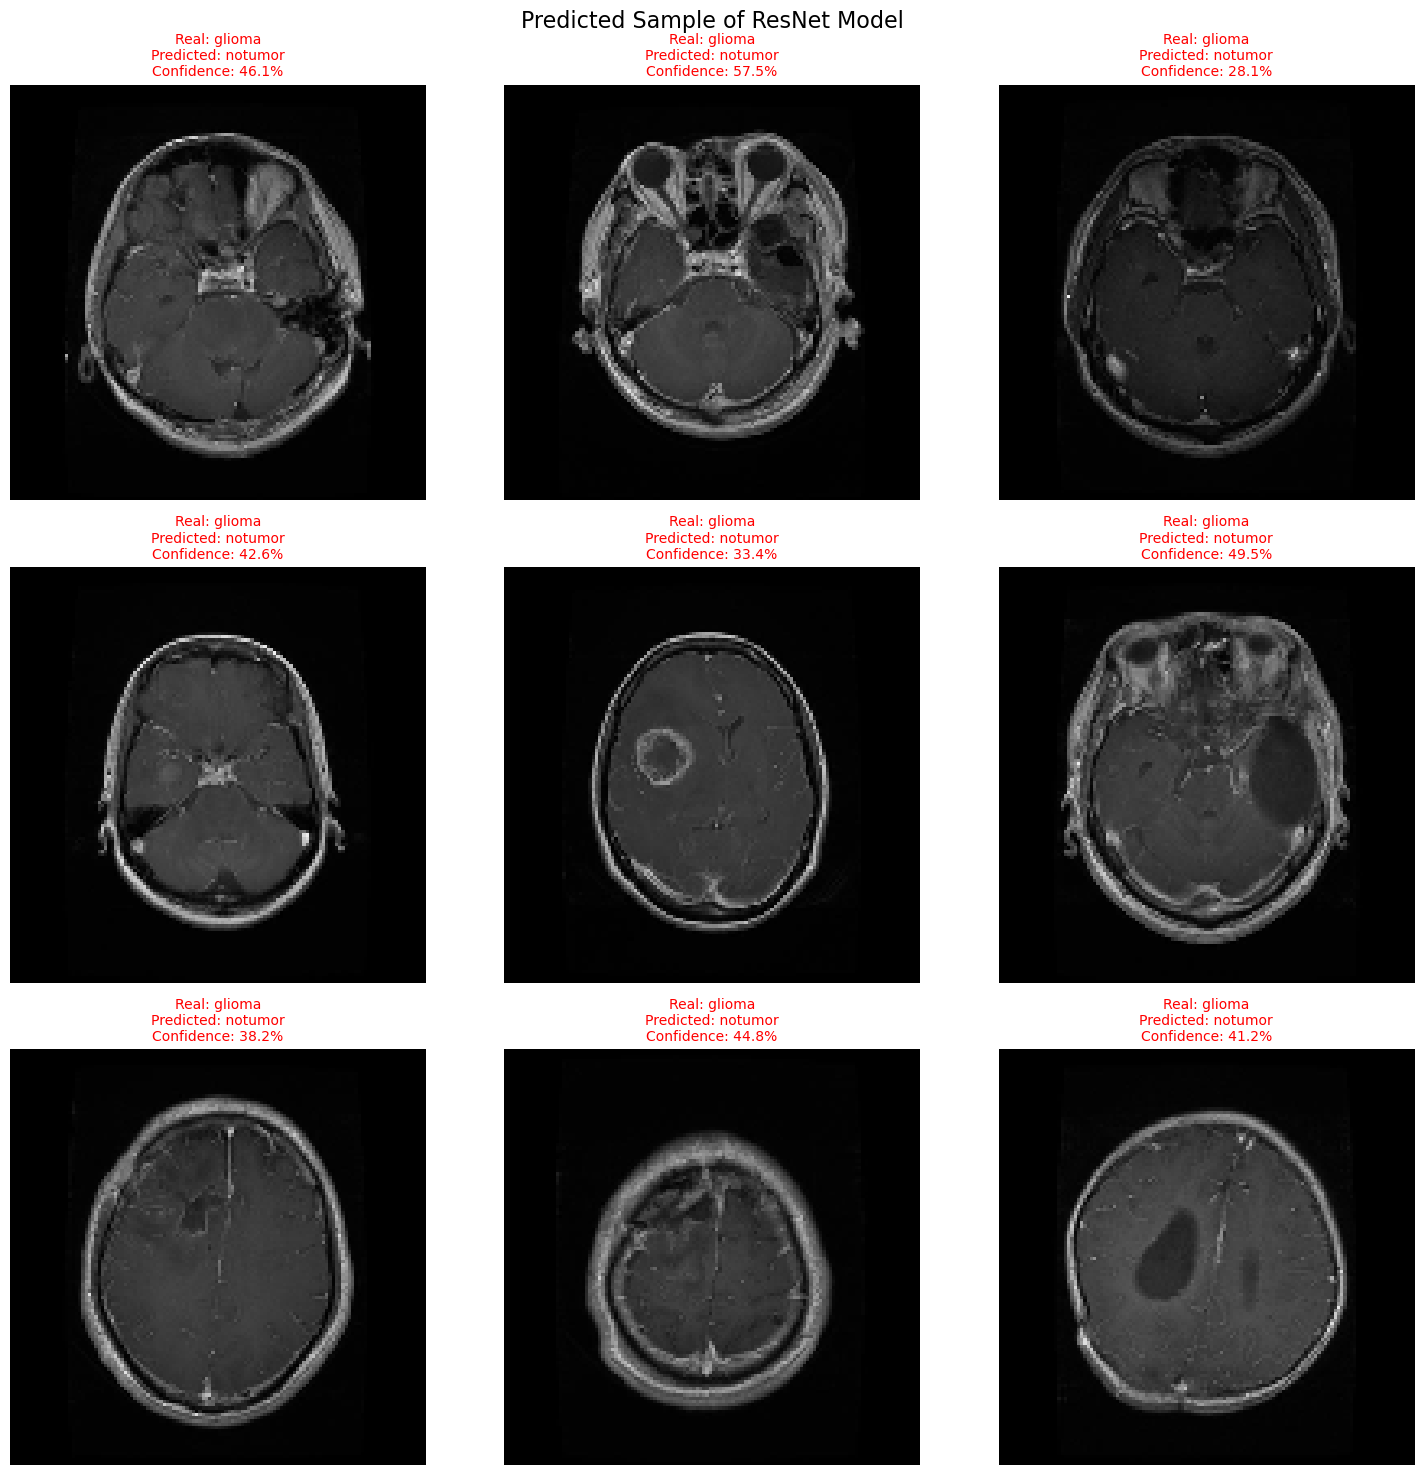

In [34]:
def show_predictions(model, model_name, num_samples=9):
   
    test_generator.reset()
    images, true_labels = next(test_generator)
    predictions = model.predict(images)
    
    plt.figure(figsize=(15, 15))
    
    for i in range(min(num_samples, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        
        true_class = CLASSES[np.argmax(true_labels[i])]
        pred_class = CLASSES[np.argmax(predictions[i])]
        confidence = np.max(predictions[i]) * 100
        
        color = 'green' if true_class == pred_class else 'red'
        
        plt.title(f'Real: {true_class}\nPredicted: {pred_class}\n'
                 f'Confidence: {confidence:.1f}%',
                 color=color, fontsize=10)
        plt.axis('off')
    
    plt.suptitle(f'Predicted Sample of {model_name}', fontsize=16, y=0.98)
    plt.tight_layout()
    plt.show()

show_predictions(model_3, 'ResNet Model')

# Save Models

# Summery & Conclusion

In [38]:
print("\n" + "="*70)
print("Project Results Summary")
print("="*70)

print("\n1. Implemented Models:")
print("   - Simple CNN: A simple model with 3 convolutional layers")
print("   - VGG-like CNN: A deeper model with BatchNormalization")
print("   - ResNet-like: A model with Skip Connections")

print("\n2. Best Model:")
best_model_idx = comparison_df['Accuracy'].idxmax()
best_model_name = comparison_df.loc[best_model_idx, 'Model']
best_accuracy = comparison_df.loc[best_model_idx, 'Accuracy']
print(f"   {best_model_name} with an accuracy of {best_accuracy:.4f}")

print("\n3. Overall Comparison:")
print(comparison_df.to_string(index=False))

print("\n4. Important Notes:")
print("   - All models were trained with Data Augmentation")
print("   - EarlyStopping and ReduceLROnPlateau were used")
print("   - Accuracy, Precision, Recall, and F1-Score metrics were calculated")
print("   - Confusion Matrix was plotted for each model")

print("\n" + "="*70)
print("End of Project")
print("="*70)


Project Results Summary

1. Implemented Models:
   - Simple CNN: A simple model with 3 convolutional layers
   - VGG-like CNN: A deeper model with BatchNormalization
   - ResNet-like: A model with Skip Connections

2. Best Model:
   VGG with an accuracy of 0.3750

3. Overall Comparison:
     Model  Accuracy  Precision  Recall  F1-Score
Simple CNN     0.350   0.355671   0.350  0.303442
       VGG     0.375   0.353070   0.375  0.299409
    ResNet     0.250   0.062500   0.250  0.100000

4. Important Notes:
   - All models were trained with Data Augmentation
   - EarlyStopping and ReduceLROnPlateau were used
   - Accuracy, Precision, Recall, and F1-Score metrics were calculated
   - Confusion Matrix was plotted for each model

End of Project
